In [1]:
# Clone the entire repo.
!git clone -l -s https://github.com/DangDecTen/parallel-image-stitching.git cloned-repo
%cd cloned-repo
!ls

Cloning into 'cloned-repo'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 17 (delta 1), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 12.11 KiB | 12.11 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/cloned-repo
Makefile  make_synthetic_pair.py  README.md  src


In [2]:
# Get the stb headers
%%bash
cd src
wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h
ls

common.h
io.h
main.cpp
stb_image.h
stb_image_write.h
stitch.h
v0_seq.cpp


In [3]:
# Compile
%%bash
make

g++ -O2 -std=c++17 src/main.cpp src/v0_seq.cpp -o stitch


In [ ]:
# Create synthetic data
# %%bash
# python -m data.make_synthetic_pair

# Get online data
import urllib.request
urllib.request.urlretrieve('http://www.ic.unicamp.br/~helio/imagens_registro/foto1A.jpg', "data/im_a.jpg")
urllib.request.urlretrieve('http://www.ic.unicamp.br/~helio/imagens_registro/foto1B.jpg', "data/im_b.jpg")


('data/im_b.jpg', <http.client.HTTPMessage at 0x7c1254e5f9b0>)

In [15]:
# Stitch right image to left image
%%bash
./stitch data/im_b.jpg data/im_a.jpg pano_v0.png --version 0 --runs 5

version=0  input=1024x683  runs=5  device=CPU(single thread)
keypoints A/B: 2957/2473  matches: 762  inliers: 727  stitched: yes
H = [ 0.77159  0.04285  444.42522; -0.13477  0.91860  74.51600; -0.000210 -0.000026  1.000000]
stage times (ms, mean | min):
  gray           2.287 |     2.241
  blur          24.330 |    23.719
  fast          57.981 |    56.290
  brief         12.126 |    11.115
  match        292.586 |   277.385
  ransac        11.378 |    10.498
  warp          35.872 |    34.948
  h2d            0.000 |     0.000
  d2h            0.000 |     0.000
  total(e2e)   436.561 |   419.217
  kernels      436.560
CSV,0,1024,683,2.2865,24.3304,57.9812,12.1259,292.5857,11.3780,35.8723,0.0000,0.0000,436.5608
panorama 1646x816 -> pano_v0.png


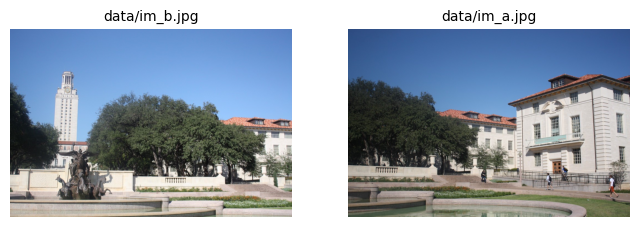

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

imgs = ["data/im_b.jpg", "data/im_a.jpg"]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for i, ax in enumerate(axes.ravel()):
  ax.imshow(Image.open(imgs[i]))
  ax.set_title(imgs[i], fontsize=10)
  ax.axis('off')


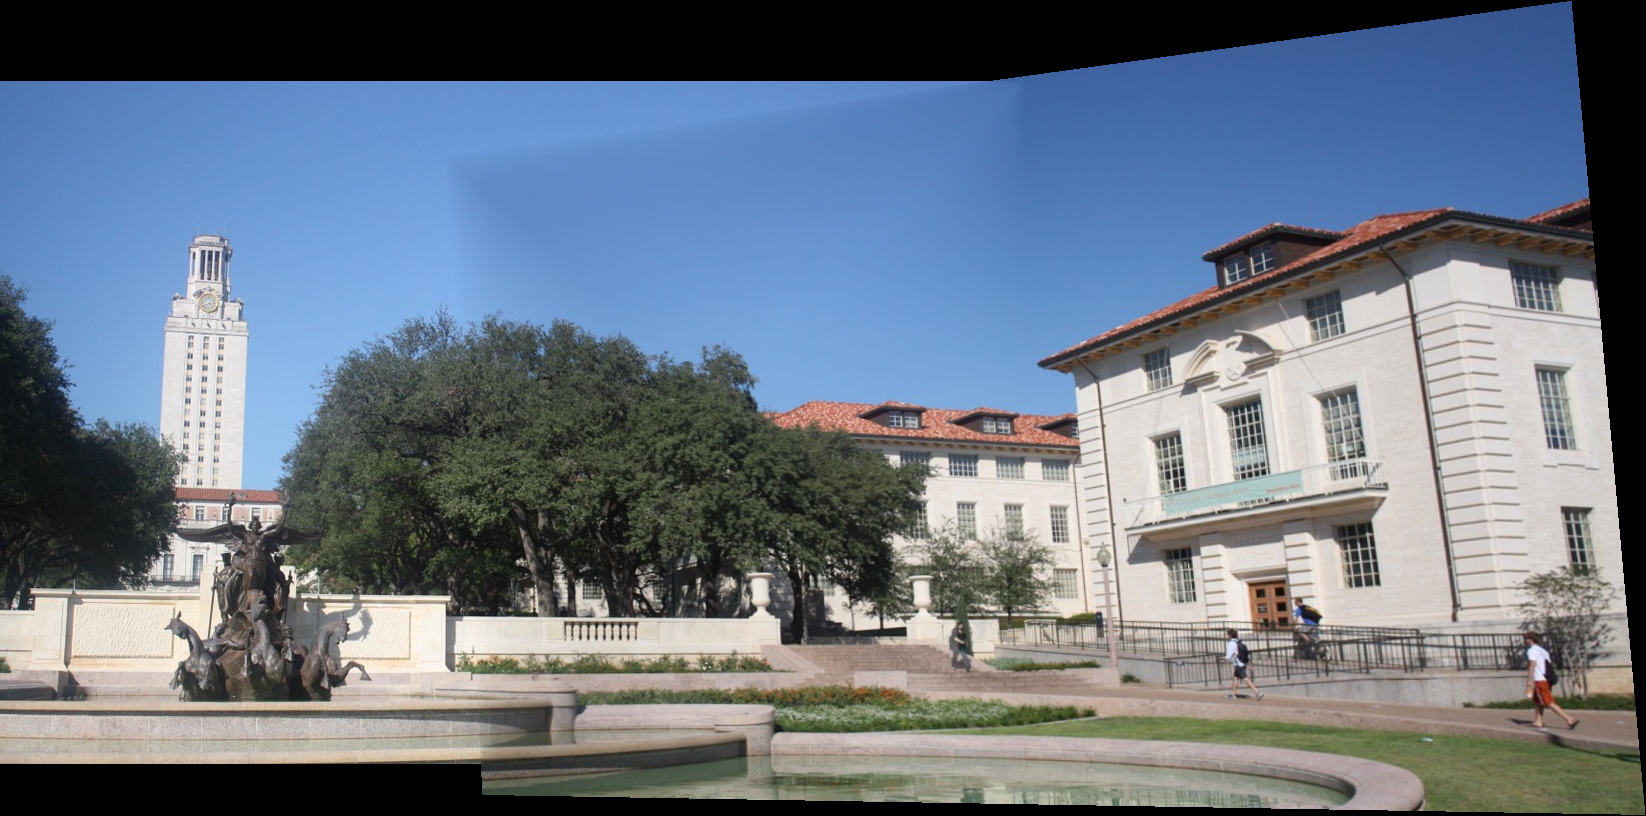

In [18]:
# View the result
from IPython.display import Image, display
display(Image("pano_v0.png"))